# Цифровая примерка распила
**Воспроизводимый модельный эксперимент для темы Segezha Group.**

Помогает ли учёт погрешности измерений получать больше досок заданного сечения? Для каждого модельного бревна алгоритм получает измеренные полуоси, а выход всех трёх вариантов оценивается по общей истинной геометрии.

**Запуск:** откройте ноутбук в Jupyter или Google Colab и выполните все ячейки по порядку. Нужны NumPy и Matplotlib. Исходные данные генерируются внутри ноутбука. В каталоге `sawing_results` появятся CSV и два рисунка. Для повторения опыта из заявки оставьте параметры по умолчанию.

## 1. Параметры пилота
Размеры указаны в миллиметрах. По умолчанию моделируются 200 прямых эллиптических брёвен, пропил 3 мм, три ширины доски. При необходимости измените число брёвен и зерно генератора.

In [1]:
from pathlib import Path
import csv
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Rectangle

from IPython.display import Image, display
ROOT = Path('sawing_results')
ROOT.mkdir(exist_ok=True)
SEED = 2026
N_LOGS = 200
if N_LOGS < 1:
    raise ValueError("Число брёвен должно быть положительным")
THICK, KERF = 25, 3
WIDTHS = np.array([100, 125, 150])
ERRORS = [-3, 0, 3]
# Общие для всех способов допустимые блоки из одинаковых досок в одном слое.
OPTIONS = [(w, n) for w in WIDTHS for n in (1, 2, 3, 4)]
SPAN = np.array([w*n + (n-1)*KERF for w, n in OPTIONS])
AREA = np.array([w*n*THICK for w, n in OPTIONS])
CENTRES = np.arange(-10, 11)*(THICK+KERF)
LAYOUTS = [(rot, shift) for rot in (0, 1) for shift in (0, 7, 14, 21)]

EDGE = np.array([[max(abs(-span/2+k*(w+KERF)), abs(-span/2+k*(w+KERF)+w)) if k<n else np.inf for k in range(4)] for span,(w,n) in zip(SPAN,OPTIONS)])
UNIT = np.array([w*THICK for w,n in OPTIONS])

## 2. Допустимость и выбор схемы
Доска годна, если все её углы находятся внутри узкого торца. Алгоритм сравнивает блоки досок по слоям с учётом пропила. Вариант `fixed` подбирает доски при одном фиксированном положении слоёв, `nominal` перебирает восемь положений по единственному измерению, `expected` оценивает эти же положения на девяти равновесных вариантах измеренных полуосей. При окончательной проверке годность определяется для каждой доски отдельно.

In [2]:
def fits(axes, rot, shift):
    """Все четыре угла крайней доски должны лежать внутри верхнего сечения."""
    a,b = axes[::-1] if rot else axes
    y = np.abs(CENTRES + shift) + THICK/2
    return (y[:,None]/b)**2 + (SPAN[None,:]/(2*a))**2 <= 1

def plan(measured, mode):
    layouts = LAYOUTS[:1] if mode == 'fixed' else LAYOUTS
    offsets = [(0,0)] if mode != 'expected' else [(x,y) for x in ERRORS for y in ERRORS]
    best = None
    for rot,shift in layouts:
        scores = np.zeros((len(CENTRES),len(OPTIONS)))
        possible = np.zeros_like(scores,dtype=bool)
        y = np.abs(CENTRES+shift)+THICK/2
        for offset in offsets:
            axes = measured+offset
            a,b = axes[::-1] if rot else axes
            valid = (y[:,None,None]/b)**2+(EDGE[None,:,:]/a)**2<=1
            scores += valid.sum(axis=2)*UNIT
            possible |= fits(axes,rot,shift)
        scores *= possible/len(offsets)
        # Пустой слой допустим. При равной оценке выбирается первый вариант.
        idx = scores.argmax(axis=1)
        rows = np.arange(len(idx))
        gain = scores[rows,idx]
        candidate = (rot,shift,idx,gain>0)
        if best is None or gain.sum()>best[0]:
            best = (gain.sum(),candidate)
    return best[1]

def individual(axes,layout):
    """Центральные доски слоя могут остаться годными даже при браке крайних."""
    rot,shift,idx,used = layout; a,b=axes[::-1] if rot else axes
    total=0
    for row in np.flatnonzero(used):
        w,n=OPTIONS[idx[row]]
        for k in range(n):
            l=-SPAN[idx[row]]/2+k*(w+KERF)
            if (max(abs(l),abs(l+w))/a)**2+((abs(CENTRES[row]+shift)+THICK/2)/b)**2<=1:
                total+=w*THICK
    return total

## 3. Общая выборка и расчёт выхода
Обе полуоси увеличиваются к комлю линейно на одну величину. Для полуосей верхнего торца $a,b$ и приращения $t$ средняя площадь сечения равна $π[ab+(a+b)t/2+t²/3]$. Доля объёма полноразмерных досок равна отношению суммы площадей их сечений к этой средней площади. При выборе раскладки истинные размеры скрыты.

In [3]:
rng=np.random.default_rng(SEED); rows=[]; example=None
for i in range(N_LOGS):
    axes=np.array([rng.uniform(145,220),0.])
    axes[1]=axes[0]*rng.uniform(.72,.98)
    taper=rng.uniform(5,15)
    measured=axes+rng.choice(ERRORS,2)
    # Полуоси линейно возрастают к комлю; объём интегрируется точно.
    a,b=axes; mean_section=np.pi*(a*b+(a+b)*taper/2+taper**2/3)
    plans={m:plan(measured,m) for m in ('fixed','nominal','expected')}
    ys={m:100*individual(axes,p)/mean_section for m,p in plans.items()}
    rows.append(dict(id=i+1,a=a,b=b,taper=taper,measured_a=measured[0],measured_b=measured[1],**ys))
    if example is None and ys['expected']-ys['nominal']>1:
        example=(i+1,axes,measured,plans,ys)
with (ROOT/'results.csv').open('w',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=rows[0]);writer.writeheader();writer.writerows(rows)

print(f"Рассчитано брёвен: {len(rows)}. Сохранено: {ROOT / 'results.csv'}")

Рассчитано брёвен: 200. Сохранено: sawing_results/results.csv


## 4. Итог и разброс по брёвнам
Среднее даёт одинаковый вес каждому бревну. Для парной разности вычитаем из выхода с учётом погрешности выход по одному измерению. Единица разности — процентный пункт.

Фиксированное положение: 63.53%
По измерению: 64.14%
С учётом погрешности: 67.35%
Средняя разность: +3.21 п. п.
Выигрыши: 78, совпадения: 33, потери: 89


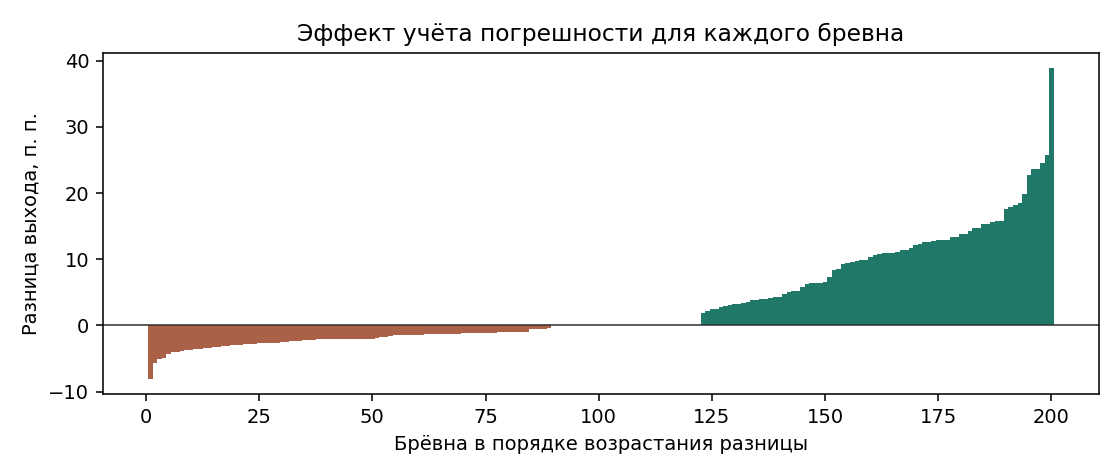

In [4]:
modes = ('fixed', 'nominal', 'expected')
values = np.array([[row[m] for m in modes] for row in rows])
assert np.all((0 <= values) & (values <= 100))
for label, mean in zip(('Фиксированное положение', 'По измерению', 'С учётом погрешности'), values.mean(axis=0)):
    print(f'{label}: {mean:.2f}%')
delta = values[:, 2] - values[:, 1]
print(f'Средняя разность: {delta.mean():+.2f} п. п.')
print(f'Выигрыши: {(delta > 1e-9).sum()}, совпадения: {(np.abs(delta) <= 1e-9).sum()}, потери: {(delta < -1e-9).sum()}')

v = np.sort(delta)
fig, ax = plt.subplots(figsize=(8,3.4))
ax.bar(np.arange(1,len(v)+1), v, width=1, color=np.where(v < 0, '#AA6147', '#207968'))
ax.axhline(0, color='#303030', linewidth=.8)
ax.set(xlabel='Брёвна в порядке возрастания разницы', ylabel='Разница выхода, п. п.', title='Эффект учёта погрешности для каждого бревна')
fig.tight_layout()
fig.savefig(ROOT/'differences.png', dpi=140)
plt.close(fig)
display(Image(filename=str(ROOT/'differences.png')))

## 5. Две карты распила одного бревна
Для иллюстрации выбирается первый пример с выигрышем более одного процентного пункта. Зелёный прямоугольник — доска, которая проходит по габаритам. Оранжевый — доска, у которой угол вышел за границу. Этот пример иллюстрирует механизм выигрыша; о частоте потерь судите по графику всей выборки.

Бревно № 2


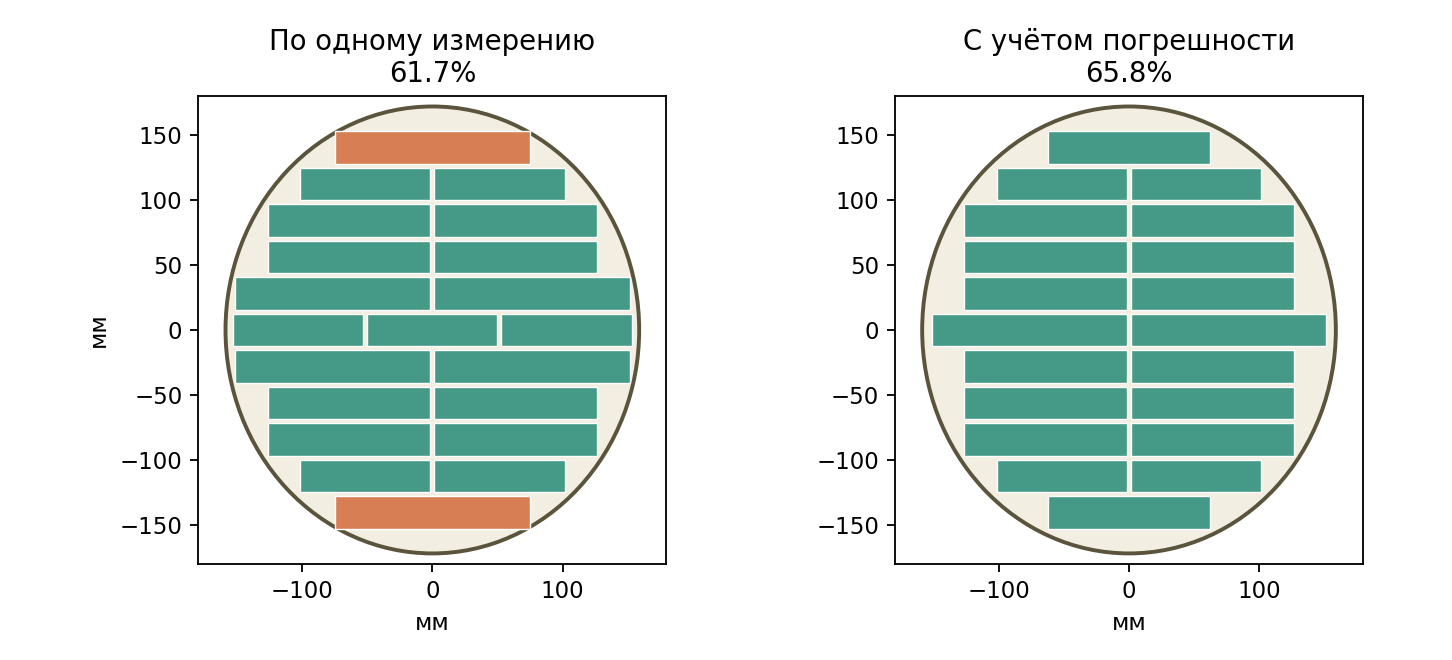

In [5]:
def draw(ex):
    number,axes,measured,plans,ys=ex
    fig,axs=plt.subplots(1,2,figsize=(8.8,4))
    for ax,mode,title in zip(axs,['nominal','expected'],['По одному измерению','С учётом погрешности']):
        rot,shift,idx,used=plans[mode]; a,b=axes[::-1] if rot else axes
        ax.add_patch(Ellipse((0,0),2*a,2*b,fc='#f2eee1',ec='#5b543c',lw=1.7))
        for row in np.flatnonzero(used):
            w,n=OPTIONS[idx[row]]
            for k in range(n):
                left=-SPAN[idx[row]]/2 + k*(w+KERF)
                top=abs(CENTRES[row]+shift)+THICK/2
                good=((max(abs(left),abs(left+w))/a)**2+(top/b)**2)<=1
                ax.add_patch(Rectangle((left,CENTRES[row]+shift-THICK/2),w,THICK,fc='#449a87' if good else '#d77e55',ec='white',lw=.6))
        ax.set(xlim=(-max(axes)-8,max(axes)+8),ylim=(-max(axes)-8,max(axes)+8),aspect='equal',xlabel='мм',title=title+'\n'+f'{ys[mode]:.1f}%')
    axs[0].set_ylabel('мм'); fig.tight_layout();fig.savefig(ROOT/'example.png',dpi=165);plt.close(fig)

if example is None:
    print('В этой выборке нет примера с выигрышем более 1 п. п.')
else:
    print(f'Бревно № {example[0]}')
    draw(example)
    display(Image(filename=str(ROOT/'example.png')))

## Что показал пилот
При параметрах заявки средний выход составил 63,53%, 64,14% и 67,35% соответственно. Учёт погрешности дал **+3,21 п. п.** по сравнению с выбором по одному измерению. Метод выиграл на 78 брёвнах, дал тот же результат на 33 и проиграл на 89. В этой модели величина выигрышей перекрыла потери.

Расчёт учитывает только геометрию прямых брёвен, а распределение ошибок алгоритма согласовано с генератором. Для решения о применении нужны реальные профили, стоимость изделий, сорт, допустимый обзол и ограничения станка.